In [1]:
# !pip install adjustText

# RQ2: Effectiveness vs Efficiency

In [1]:
from pathlib import Path
import pandas as pd
import json

In [2]:
results_folder = Path("test_service_10")
vram_path = Path("vram_peak_summary.csv")

In [3]:
result_files = [
    file
    for file in results_folder.glob("*.csv")
    if file.name != "emissions.csv"
]
result_files

[PosixPath('test_service_10/bi-encoder_Qwen-Qwen3-Embedding-8B.csv'),
 PosixPath('test_service_10/cross-encoder_Qwen-Qwen3-Reranker-4B.csv'),
 PosixPath('test_service_10/colbert_mixedbread-ai-mxbai-colbert-large-v1.csv'),
 PosixPath('test_service_10/llm_qwen2.5:14b.csv'),
 PosixPath('test_service_10/cross-encoder_Qwen-Qwen3-Reranker-8B.csv'),
 PosixPath('test_service_10/bi-encoder_Qwen-Qwen3-Embedding-4B.csv'),
 PosixPath('test_service_10/bi-encoder_BAAI-bge-large-en-v1.5.csv'),
 PosixPath('test_service_10/cross-encoder_BAAI-bge-reranker-v2-m3.csv'),
 PosixPath('test_service_10/colbert_LiquidAI-LFM2-ColBERT-350M.csv'),
 PosixPath('test_service_10/llm_qwen2.5:32b.csv'),
 PosixPath('test_service_10/colbert_lightonai-Reason-ModernColBERT.csv'),
 PosixPath('test_service_10/llm_phi4:14b.csv'),
 PosixPath('test_service_10/cross-encoder_mixedbread-ai-mxbai-rerank-large-v2.csv'),
 PosixPath('test_service_10/cross-encoder_Qwen-Qwen3-Reranker-0.6B.csv'),
 PosixPath('test_service_10/bi-encoder_Qw

In [4]:
efficiency_files = list(
    results_folder.glob("*_efficiency.json")
)
efficiency_files

[PosixPath('test_service_10/colbert_lightonai-Reason-ModernColBERT_efficiency.json'),
 PosixPath('test_service_10/llm_qwen2.5:32b_efficiency.json'),
 PosixPath('test_service_10/cross-encoder_Qwen-Qwen3-Reranker-4B_efficiency.json'),
 PosixPath('test_service_10/bi-encoder_Qwen-Qwen3-Embedding-4B_efficiency.json'),
 PosixPath('test_service_10/colbert_LiquidAI-LFM2-ColBERT-350M_efficiency.json'),
 PosixPath('test_service_10/cross-encoder_mixedbread-ai-mxbai-rerank-large-v2_efficiency.json'),
 PosixPath('test_service_10/cross-encoder_BAAI-bge-reranker-v2-m3_efficiency.json'),
 PosixPath('test_service_10/llm_phi4:14b_efficiency.json'),
 PosixPath('test_service_10/llm_llama3.1:8b_efficiency.json'),
 PosixPath('test_service_10/bi-encoder_BAAI-bge-large-en-v1.5_efficiency.json'),
 PosixPath('test_service_10/llm_qwen3:32b_efficiency.json'),
 PosixPath('test_service_10/llm_qwen2.5:7b_efficiency.json'),
 PosixPath('test_service_10/cross-encoder_Qwen-Qwen3-Reranker-0.6B_efficiency.json'),
 PosixPa

In [5]:
print("Model result files:", len(result_files))
print("Efficiency files:", len(efficiency_files))

Model result files: 20
Efficiency files: 20


## combine all models dfs


In [7]:

all_models_results = []

for file_path in result_files:
    df = pd.read_csv(file_path)
    all_models_results.append(df)

# len(all_models_results)

results_df = pd.concat(
    all_models_results,
    ignore_index=True
)

len(results_df)

22000

In [8]:
results_df["model_name"].nunique()

20

In [9]:
results_df.columns.tolist()

['routing_method',
 'query',
 'raw_response',
 'predicted_label',
 'model_name',
 'latency_ms',
 'prompt_tokens',
 'completion_tokens',
 'total_tokens',
 'query_id',
 'expected_service',
 'is_correct',
 'error',
 'specialist_service_count',
 'total_service_count']

In [10]:
results_df.head()

,routing_method,query,raw_response,predicted_label,model_name,latency_ms,prompt_tokens,completion_tokens,total_tokens,query_id,expected_service,is_correct,error,specialist_service_count,total_service_count
0,bi-encoder,Statement 1 | If a group has an element of ord...,NaN,abstract_algebra,Qwen/Qwen3-Embedding-8B,377.911569,65,0,65,0,abstract_algebra,True,NaN,10,11
1,bi-encoder,"Statement 1 | If G, H and K are groups of orde...",NaN,abstract_algebra,Qwen/Qwen3-Embedding-8B,98.242861,58,0,58,1,abstract_algebra,True,NaN,10,11
2,bi-encoder,"(Z,*) is a group with a*b = a+b+1 for all a, b...",NaN,abstract_algebra,Qwen/Qwen3-Embedding-8B,87.710913,28,0,28,2,abstract_algebra,True,NaN,10,11
3,bi-encoder,"Statement 1 | For any two groups G and G', the...",NaN,abstract_algebra,Qwen/Qwen3-Embedding-8B,55.024976,39,0,39,3,abstract_algebra,True,NaN,10,11
4,bi-encoder,"Let A and B be sets, f: A -> B and g: B -> A b...",NaN,formal_logic,Qwen/Qwen3-Embedding-8B,38.079356,63,0,63,4,abstract_algebra,False,NaN,10,11


In [12]:
results_summary_df = (
    results_df
    .groupby(["routing_method", "model_name"])
    .agg(
        accuracy=("is_correct", "mean"),
        median_latency_ms=("latency_ms", "median")
    )
    .reset_index()
)

results_summary_df

,routing_method,model_name,accuracy,median_latency_ms
0,bi-encoder,BAAI/bge-large-en-v1.5,0.797273,14.180362
1,bi-encoder,Qwen/Qwen3-Embedding-0.6B,0.734545,27.447876
2,bi-encoder,Qwen/Qwen3-Embedding-4B,0.748182,35.036823
3,bi-encoder,Qwen/Qwen3-Embedding-8B,0.775455,36.528761
4,bi-encoder,sentence-transformers/all-MiniLM-L6-v2,0.730000,4.864217
5,colbert,LiquidAI/LFM2-ColBERT-350M,0.731818,14.593067
6,colbert,colbert-ir/colbertv2.0,0.629091,9.383726
7,colbert,lightonai/Reason-ModernColBERT,0.759091,16.156632
8,colbert,mixedbread-ai/mxbai-colbert-large-v1,0.720000,16.010283
9,cross-encoder,BAAI/bge-reranker-v2-m3,0.681818,75.270379


In [13]:
results_summary_df["accuracy_percent"] = (
    results_summary_df["accuracy"] * 100
).round(2)

results_summary_df

,routing_method,model_name,accuracy,median_latency_ms,accuracy_percent
0,bi-encoder,BAAI/bge-large-en-v1.5,0.797273,14.180362,79.73
1,bi-encoder,Qwen/Qwen3-Embedding-0.6B,0.734545,27.447876,73.45
2,bi-encoder,Qwen/Qwen3-Embedding-4B,0.748182,35.036823,74.82
3,bi-encoder,Qwen/Qwen3-Embedding-8B,0.775455,36.528761,77.55
4,bi-encoder,sentence-transformers/all-MiniLM-L6-v2,0.730000,4.864217,73.00
5,colbert,LiquidAI/LFM2-ColBERT-350M,0.731818,14.593067,73.18
6,colbert,colbert-ir/colbertv2.0,0.629091,9.383726,62.91
7,colbert,lightonai/Reason-ModernColBERT,0.759091,16.156632,75.91
8,colbert,mixedbread-ai/mxbai-colbert-large-v1,0.720000,16.010283,72.00
9,cross-encoder,BAAI/bge-reranker-v2-m3,0.681818,75.270379,68.18


## combine efficiency df

In [11]:
# with open(efficiency_files[0], "r") as f:
#     efficiency_example = json.load(f)

# efficiency_example

In [14]:
all_efficiency_results = []

for file_path in efficiency_files:

    with open(file_path, "r") as f:
        data = json.load(f)

    all_efficiency_results.append({
        "routing_method": data["routing_method"],
        "model_name": data["model_name"],
        "specialist_service_count": data["specialist_service_count"],
        "total_queries": data["total_queries"],
        "total_energy_kwh": data["total_energy_kwh"],
        "energy_per_query_kwh": data["energy_per_query_kwh"],
        "energy_per_query_mwh": data["energy_per_query_kwh"] * 1_000_000,
        "total_co2_kg": data["total_co2_kg"],
        "co2_per_query_kg": data["co2_per_query_kg"],
        "co2_per_query_mg": data["co2_per_query_kg"]* 1_000_000,
    })

In [15]:
efficiency_df = pd.DataFrame(all_efficiency_results)

In [17]:
efficiency_df

,routing_method,model_name,specialist_service_count,total_queries,total_energy_kwh,energy_per_query_kwh,energy_per_query_mwh,total_co2_kg,co2_per_query_kg,co2_per_query_mg
0,colbert,lightonai/Reason-ModernColBERT,10,1100,0.001507,1.369828e-06,1.369828,0.000827,7.516138e-07,0.751614
1,llm,qwen2.5:32b,10,1100,0.045927,4.175138e-05,41.751380,0.025200,2.290865e-05,22.908648
2,cross-encoder,Qwen/Qwen3-Reranker-4B,10,1100,0.014784,1.343987e-05,13.439873,0.008112,7.374351e-06,7.374351
3,bi-encoder,Qwen/Qwen3-Embedding-4B,10,1100,0.002315,2.104779e-06,2.104779,0.001270,1.154875e-06,1.154875
4,colbert,LiquidAI/LFM2-ColBERT-350M,10,1100,0.001459,1.326336e-06,1.326336,0.000801,7.277497e-07,0.727750
5,cross-encoder,mixedbread-ai/mxbai-rerank-large-v2,10,1100,0.007708,7.007085e-06,7.007085,0.004229,3.844732e-06,3.844732
6,cross-encoder,BAAI/bge-reranker-v2-m3,10,1100,0.010644,9.676433e-06,9.676433,0.005840,5.309382e-06,5.309382
7,llm,phi4:14b,10,1100,0.028382,2.580192e-05,25.801925,0.015573,1.415731e-05,14.157310
8,llm,llama3.1:8b,10,1100,0.034321,3.120085e-05,31.200851,0.018832,1.711966e-05,17.119658
9,bi-encoder,BAAI/bge-large-en-v1.5,10,1100,0.001510,1.373057e-06,1.373057,0.000829,7.533851e-07,0.753385


## Merge two dfs together 


results_summary_df
> accuracy, median, latency

efficiency_df
> energy, CO₂

In [15]:
# set(results_summary_df["model_name"]) == set(efficiency_df["model_name"])

In [18]:
rq3_df = results_summary_df.merge(
    efficiency_df[
        [
            "model_name",
            "specialist_service_count",
            "total_queries",
            "total_energy_kwh",
            "energy_per_query_kwh",
            "energy_per_query_mwh",
            "total_co2_kg",
            "co2_per_query_kg",
            "co2_per_query_mg"
        ]
    ],
    on="model_name",
    how="left",
    validate="one_to_one"
)

In [19]:
rq3_df

,routing_method,model_name,accuracy,median_latency_ms,accuracy_percent,specialist_service_count,total_queries,total_energy_kwh,energy_per_query_kwh,energy_per_query_mwh,total_co2_kg,co2_per_query_kg,co2_per_query_mg
0,bi-encoder,BAAI/bge-large-en-v1.5,0.797273,14.180362,79.73,10,1100,0.001510,1.373057e-06,1.373057,0.000829,7.533851e-07,0.753385
1,bi-encoder,Qwen/Qwen3-Embedding-0.6B,0.734545,27.447876,73.45,10,1100,0.001483,1.347787e-06,1.347787,0.000813,7.395199e-07,0.739520
2,bi-encoder,Qwen/Qwen3-Embedding-4B,0.748182,35.036823,74.82,10,1100,0.002315,2.104779e-06,2.104779,0.001270,1.154875e-06,1.154875
3,bi-encoder,Qwen/Qwen3-Embedding-8B,0.775455,36.528761,77.55,10,1100,0.003981,3.619515e-06,3.619515,0.002185,1.985999e-06,1.985999
4,bi-encoder,sentence-transformers/all-MiniLM-L6-v2,0.730000,4.864217,73.00,10,1100,0.000467,4.242501e-07,0.424250,0.000256,2.327826e-07,0.232783
5,colbert,LiquidAI/LFM2-ColBERT-350M,0.731818,14.593067,73.18,10,1100,0.001459,1.326336e-06,1.326336,0.000801,7.277497e-07,0.727750
6,colbert,colbert-ir/colbertv2.0,0.629091,9.383726,62.91,10,1100,0.000943,8.573596e-07,0.857360,0.000517,4.704264e-07,0.470426
7,colbert,lightonai/Reason-ModernColBERT,0.759091,16.156632,75.91,10,1100,0.001507,1.369828e-06,1.369828,0.000827,7.516138e-07,0.751614
8,colbert,mixedbread-ai/mxbai-colbert-large-v1,0.720000,16.010283,72.00,10,1100,0.001507,1.369796e-06,1.369796,0.000827,7.515960e-07,0.751596
9,cross-encoder,BAAI/bge-reranker-v2-m3,0.681818,75.270379,68.18,10,1100,0.010644,9.676433e-06,9.676433,0.005840,5.309382e-06,5.309382


## load vram

In [20]:
vram_df = pd.read_csv(vram_path)

vram_df

,model_name,specialist_service_count,peak_vram_mib,peak_vram_gib
0,BAAI/bge-large-en-v1.5,10,1869,1.83
1,Qwen/Qwen3-Embedding-0.6B,10,1861,1.82
2,Qwen/Qwen3-Embedding-4B,10,8569,8.37
3,Qwen/Qwen3-Embedding-8B,10,15323,14.96
4,sentence-transformers/all-MiniLM-L6-v2,10,647,0.63
5,BAAI/bge-reranker-v2-m3,10,3785,3.70
6,Qwen/Qwen3-Reranker-0.6B,10,2925,2.86
7,Qwen/Qwen3-Reranker-4B,10,11201,10.94
8,Qwen/Qwen3-Reranker-8B,10,19983,19.51
9,mixedbread-ai/mxbai-rerank-large-v2,10,6049,5.91


In [21]:
set(rq3_df["model_name"]) == set(vram_df["model_name"])

True

In [22]:
rq3_df_full = rq3_df.merge(
    vram_df[
        [
            "model_name",
            "peak_vram_mib",
            "peak_vram_gib"
        ]
    ],
    on="model_name",
    how="left",
    validate="one_to_one"
)

# Full Data combined vram + efficiency + models

In [23]:
rq3_df_full.columns

Index(['routing_method', 'model_name', 'accuracy', 'median_latency_ms',
       'accuracy_percent', 'specialist_service_count', 'total_queries',
       'total_energy_kwh', 'energy_per_query_kwh', 'energy_per_query_mwh',
       'total_co2_kg', 'co2_per_query_kg', 'co2_per_query_mg', 'peak_vram_mib',
       'peak_vram_gib'],
      dtype='object')

In [24]:
rq3_core_df = rq3_df_full[
    [
        "routing_method",
        "model_name",
        "accuracy_percent",
        "median_latency_ms",
        "energy_per_query_mwh",
        "co2_per_query_mg",
        "peak_vram_gib"
    ]
].copy()

In [25]:
rq3_core_df

,routing_method,model_name,accuracy_percent,median_latency_ms,energy_per_query_mwh,co2_per_query_mg,peak_vram_gib
0,bi-encoder,BAAI/bge-large-en-v1.5,79.73,14.180362,1.373057,0.753385,1.83
1,bi-encoder,Qwen/Qwen3-Embedding-0.6B,73.45,27.447876,1.347787,0.739520,1.82
2,bi-encoder,Qwen/Qwen3-Embedding-4B,74.82,35.036823,2.104779,1.154875,8.37
3,bi-encoder,Qwen/Qwen3-Embedding-8B,77.55,36.528761,3.619515,1.985999,14.96
4,bi-encoder,sentence-transformers/all-MiniLM-L6-v2,73.00,4.864217,0.424250,0.232783,0.63
5,colbert,LiquidAI/LFM2-ColBERT-350M,73.18,14.593067,1.326336,0.727750,1.96
6,colbert,colbert-ir/colbertv2.0,62.91,9.383726,0.857360,0.470426,1.01
7,colbert,lightonai/Reason-ModernColBERT,75.91,16.156632,1.369828,0.751614,1.13
8,colbert,mixedbread-ai/mxbai-colbert-large-v1,72.00,16.010283,1.369796,0.751596,1.19
9,cross-encoder,BAAI/bge-reranker-v2-m3,68.18,75.270379,9.676433,5.309382,3.70


In [32]:
# latex_df = rq3_core_df.copy()

# latex_df.columns = [
#     "Architecture",
#     "Model",
#     "Accuracy (\\%)",
#     "Median Latency (ms/query)",
#     "Energy (mWh/query)",
#     "CO$_2$ (mg/query)",
#     "Peak VRAM (GiB)"
# ]

# latex_df["Architecture"] = latex_df["Architecture"].replace({
#     "bi-encoder": "Bi-encoder",
#     "colbert": "ColBERT",
#     "cross-encoder": "Cross-encoder",
#     "llm": "LLM"
# })

In [33]:
# latex_df.loc[
#     latex_df["Architecture"].eq(latex_df["Architecture"].shift()),
#     "Architecture"
# ] = ""

In [34]:
# latex_table = latex_df.to_latex(
#     index=False,
#     escape=False,
#     float_format="%.2f",
#     column_format="llrrrrr",
#     caption="Routing effectiveness and efficiency at the 10-specialist-service condition.",
#     label="tab:rq3_efficiency",
#     position="htbp"
# )

# print(latex_table)

\begin{table}[htbp]
\centering
\caption{Routing effectiveness and efficiency at the 10-specialist-service condition.}
\label{tab:rq3_efficiency}
\begin{tabular}{llrrrrr}
\toprule
 Architecture &                                  Model &  Accuracy (\%) &  Median Latency (ms/query) &  Energy (mWh/query) &  CO$_2$ (mg/query) &  Peak VRAM (GiB) \\
\midrule
   Bi-encoder &                 BAAI/bge-large-en-v1.5 &          79.73 &                      14.18 &                1.37 &               0.75 &             1.83 \\
              &              Qwen/Qwen3-Embedding-0.6B &          73.45 &                      27.45 &                1.35 &               0.74 &             1.82 \\
              &                Qwen/Qwen3-Embedding-4B &          74.82 &                      35.04 &                2.10 &               1.15 &             8.37 \\
              &                Qwen/Qwen3-Embedding-8B &          77.55 &                      36.53 &                3.62 &               1.99 &   

/var/folders/ry/0c4wrnjn3812nl8bhsqgwkv00000gn/T/ipykernel_11463/3340498933.py:1: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  latex_table = latex_df.to_latex(


### Plot Acc vs Latency 

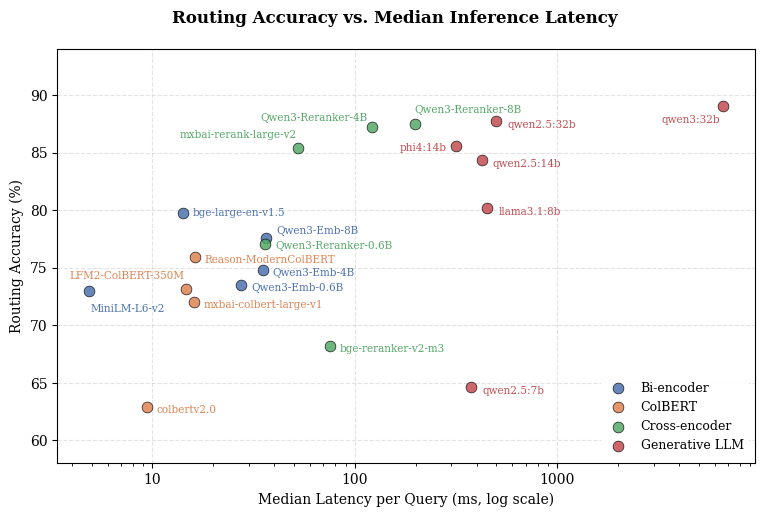

In [163]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker

mpl.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.edgecolor": "black",
    "axes.linewidth": 0.8,
})

colors = {
    "bi-encoder": "#4C72B0",
    "colbert": "#DD8452",
    "cross-encoder": "#55A868",
    "llm": "#C44E52",
}
label_map = {
    "bi-encoder": "Bi-encoder",
    "colbert": "ColBERT",
    "cross-encoder": "Cross-encoder",
    "llm": "Generative LLM",
}
approach_order = ["bi-encoder", "colbert", "cross-encoder", "llm"]

fig, ax = plt.subplots(figsize=(9, 5.6))

for method in approach_order:
    sub = rq3_core_df[rq3_core_df["routing_method"] == method]
    ax.scatter(
        sub["median_latency_ms"], sub["accuracy_percent"],
        s=60, color=colors[method], alpha=0.85,
        edgecolor="black", linewidth=0.5, zorder=3,
        label=label_map[method] 
    )

important_models = {
    # Bi-encoder
    "BAAI/bge-large-en-v1.5": "bge-large-en-v1.5",
    "Qwen/Qwen3-Embedding-0.6B": "Qwen3-Emb-0.6B",
    "Qwen/Qwen3-Embedding-4B": "Qwen3-Emb-4B",
    "Qwen/Qwen3-Embedding-8B": "Qwen3-Emb-8B",
    "sentence-transformers/all-MiniLM-L6-v2": "MiniLM-L6-v2",

    # ColBERT
    "LiquidAI/LFM2-ColBERT-350M": "LFM2-ColBERT-350M",
    "colbert-ir/colbertv2.0": "colbertv2.0",
    "lightonai/Reason-ModernColBERT": "Reason-ModernColBERT",
    "mixedbread-ai/mxbai-colbert-large-v1": "mxbai-colbert-large-v1",

    # Cross-encoder
    "BAAI/bge-reranker-v2-m3": "bge-reranker-v2-m3",
    "Qwen/Qwen3-Reranker-0.6B": "Qwen3-Reranker-0.6B",
    "Qwen/Qwen3-Reranker-4B": "Qwen3-Reranker-4B",
    "Qwen/Qwen3-Reranker-8B": "Qwen3-Reranker-8B",
    "mixedbread-ai/mxbai-rerank-large-v2": "mxbai-rerank-large-v2",

    # Generative LLM
    "llama3.1:8b": "llama3.1:8b",
    "phi4:14b": "phi4:14b",
    "qwen2.5:7b": "qwen2.5:7b",
    "qwen2.5:14b": "qwen2.5:14b",
    "qwen2.5:32b": "qwen2.5:32b",
    "qwen3:32b": "qwen3:32b",
}

label_offsets = {
    # bi-encoder
    "BAAI/bge-large-en-v1.5": (7, -2),
    "Qwen/Qwen3-Embedding-0.6B": (7, -4),
    "Qwen/Qwen3-Embedding-4B": (7, -4),
    "Qwen/Qwen3-Embedding-8B": (7, 3),
    "sentence-transformers/all-MiniLM-L6-v2": (1, -15),

    # colbert
    "LiquidAI/LFM2-ColBERT-350M": (-1, 7),
    "colbert-ir/colbertv2.0": (7, -4),
    "lightonai/Reason-ModernColBERT": (7, -4),
    "mixedbread-ai/mxbai-colbert-large-v1": (7, -4),

    # cross-encoder
    "BAAI/bge-reranker-v2-m3": (7, -4),
    "Qwen/Qwen3-Reranker-0.6B": (7, -4),
    "Qwen/Qwen3-Reranker-4B": (-3, 5),
    "Qwen/Qwen3-Reranker-8B": (0, 8),
    "mixedbread-ai/mxbai-rerank-large-v2": (-1, 8),

    # llm
    "phi4:14b": (-7, -3),
    "qwen2.5:32b": (8, -5),
    "qwen2.5:14b": (8, -5),
    "qwen2.5:7b": (8, -5),
    "llama3.1:8b": (8, -5),
    "qwen3:32b": (-2, -12),
}

for _, row in rq3_core_df.iterrows():
    if row["model_name"] in important_models:
        dx, dy = label_offsets[row["model_name"]]
        ha = "left" if dx >= 0 else "right"
        ax.annotate(
            important_models[row["model_name"]],
            (row["median_latency_ms"], row["accuracy_percent"]),
            xytext=(dx, dy), textcoords="offset points",
            ha=ha, fontsize=7.5,
            color=colors[row["routing_method"]],
        )

ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("Median Latency per Query (ms, log scale)")
ax.set_ylabel("Routing Accuracy (%)")
ax.set_ylim(58, 94)
ax.grid(True, which="major", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

fig.suptitle("Routing Accuracy vs. Median Inference Latency",
             fontsize=12, weight="bold", y=0.92)

ax.legend(loc="lower right", frameon=True, framealpha=0.9,
          edgecolor="none", fontsize=9)

plt.subplots_adjust(top=0.85)

plt.savefig("accuracy_vs_latency.pdf", bbox_inches="tight")
plt.show()

### Plot Acc vs energy

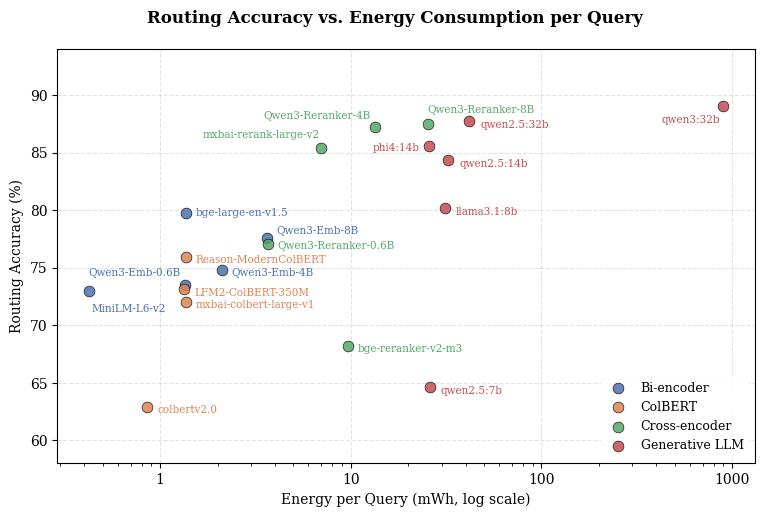

In [173]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker

mpl.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.edgecolor": "black",
    "axes.linewidth": 0.8,
})
colors = {
    "bi-encoder": "#4C72B0",
    "colbert": "#DD8452",
    "cross-encoder": "#55A868",
    "llm": "#C44E52",
}
label_map = {
    "bi-encoder": "Bi-encoder",
    "colbert": "ColBERT",
    "cross-encoder": "Cross-encoder",
    "llm": "Generative LLM",
}
approach_order = ["bi-encoder", "colbert", "cross-encoder", "llm"]

fig, ax = plt.subplots(figsize=(9, 5.6))
for method in approach_order:
    sub = rq3_core_df[rq3_core_df["routing_method"] == method]
    ax.scatter(
        sub["energy_per_query_mwh"], sub["accuracy_percent"],
        s=60, color=colors[method], alpha=0.85,
        edgecolor="black", linewidth=0.5, zorder=3,
        label=label_map[method] 
    )

important_models = {
    # Bi-encoder
    "BAAI/bge-large-en-v1.5": "bge-large-en-v1.5",
    "Qwen/Qwen3-Embedding-0.6B": "Qwen3-Emb-0.6B",
    "Qwen/Qwen3-Embedding-4B": "Qwen3-Emb-4B",
    "Qwen/Qwen3-Embedding-8B": "Qwen3-Emb-8B",
    "sentence-transformers/all-MiniLM-L6-v2": "MiniLM-L6-v2",
    # ColBERT
    "LiquidAI/LFM2-ColBERT-350M": "LFM2-ColBERT-350M",
    "colbert-ir/colbertv2.0": "colbertv2.0",
    "lightonai/Reason-ModernColBERT": "Reason-ModernColBERT",
    "mixedbread-ai/mxbai-colbert-large-v1": "mxbai-colbert-large-v1",
    # Cross-encoder
    "BAAI/bge-reranker-v2-m3": "bge-reranker-v2-m3",
    "Qwen/Qwen3-Reranker-0.6B": "Qwen3-Reranker-0.6B",
    "Qwen/Qwen3-Reranker-4B": "Qwen3-Reranker-4B",
    "Qwen/Qwen3-Reranker-8B": "Qwen3-Reranker-8B",
    "mixedbread-ai/mxbai-rerank-large-v2": "mxbai-rerank-large-v2",
    # Generative LLM
    "llama3.1:8b": "llama3.1:8b",
    "phi4:14b": "phi4:14b",
    "qwen2.5:7b": "qwen2.5:7b",
    "qwen2.5:14b": "qwen2.5:14b",
    "qwen2.5:32b": "qwen2.5:32b",
    "qwen3:32b": "qwen3:32b",
}

label_offsets = {
    # bi-encoder
    "BAAI/bge-large-en-v1.5": (7, -2),
    "Qwen/Qwen3-Embedding-0.6B": (-3, 7),
    "Qwen/Qwen3-Embedding-4B": (7, -4),
    "Qwen/Qwen3-Embedding-8B": (7, 3),
    "sentence-transformers/all-MiniLM-L6-v2": (2, -15),
    # colbert
    "LiquidAI/LFM2-ColBERT-350M": (8, -5),
    "colbert-ir/colbertv2.0": (7, -4),
    "lightonai/Reason-ModernColBERT": (7, -4),
    "mixedbread-ai/mxbai-colbert-large-v1": (7, -4),
    # cross-encoder
    "BAAI/bge-reranker-v2-m3": (7, -4),
    "Qwen/Qwen3-Reranker-0.6B": (7, -4),
    "Qwen/Qwen3-Reranker-4B": (-3, 6),
    "Qwen/Qwen3-Reranker-8B": (0, 8),
    "mixedbread-ai/mxbai-rerank-large-v2": (-1, 8),
    # llm
    "phi4:14b": (-7, -3),
    "qwen2.5:32b": (8, -5),
    "qwen2.5:14b": (8, -5),
    "qwen2.5:7b": (8, -5),
    "llama3.1:8b": (8, -5),
    "qwen3:32b": (-2, -12),
}

for _, row in rq3_core_df.iterrows():
    if row["model_name"] in important_models:
        dx, dy = label_offsets[row["model_name"]]
        ha = "left" if dx >= 0 else "right"
        ax.annotate(
            important_models[row["model_name"]],
            (row["energy_per_query_mwh"], row["accuracy_percent"]),
            xytext=(dx, dy), textcoords="offset points",
            ha=ha, fontsize=7.5,
            color=colors[row["routing_method"]],
        )

ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("Energy per Query (mWh, log scale)")
ax.set_ylabel("Routing Accuracy (%)")
ax.set_ylim(58, 94)
ax.grid(True, which="major", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

fig.suptitle("Routing Accuracy vs. Energy Consumption per Query",
             fontsize=12, weight="bold", y=0.92)

ax.legend(loc="lower right", frameon=True, framealpha=0.9,
          edgecolor="none", fontsize=9)

plt.subplots_adjust(top=0.85)
plt.savefig("accuracy_vs_energy.pdf", bbox_inches="tight")
plt.show()